# Airplane windows

Why are airplane windows rounded ovals, and not square? A window is a hole in the fuselage skin, and the skin
carries the cabin pressure. Around a hole, the stress rises above the stress far from it, and the factor between the
two is the stress concentration factor K. A pressurized cylinder carries twice as much stress around its circumference
as along its length, so on the side of a fuselage, the stress along the frames is twice the stress along the
fuselage.

Here, the skin around four kinds of window is solved with NGSolve. A round window has K = 2.5. An oval twice as tall as
it is wide has K = 1.5, the lowest of all, along its whole edge. The same oval turned on its side has 4.5. The corners
of a square window raise K without limit as they get sharper.

![The stress around a round window, a tall oval, a wide oval and a square window with round corners](../_static/gallery/airplane-windows.png){.result}

In [1]:
import math

import matplotlib.pyplot as plt
import ngsolve as ngs
from scipy.optimize import brentq
import planex as px

## The skin and its load

The example is a square of skin of 60 × 60 with a window 2 wide in its middle, so the skin is 30 times as wide as the
window and behaves almost as an endless sheet. The stress along the frames, vertical here, is 1, and the stress along
the fuselage is 0.5. The stresses are thus relative to the frame stress, and the peak along the window's edge is K.
By symmetry, a quarter of the skin is enough: the edges `symx` and `symy` lie on the symmetry lines, and the edges
`side` and `top` carry the loads.

In [2]:
def skin(window, maxh=0.05):
    quarter = px.QuickSketch().Line(30, name="symy").Line(0, 30, name="side")
    quarter = quarter.Line(-30, 0, name="top").Close(name="symx").Face()
    window.edges.name = "window"
    window.edges.maxh = maxh
    return quarter - window

`solve` meshes the skin with netgen and solves plane-stress linear elasticity with NGSolve, with third-order
elements on a curved mesh. On the free edge of the window, the only stress is the one along the edge, and it equals
the sum of the principal stresses, the trace of the stress tensor. `solve` returns this sum as a field, and its
highest and lowest value along the window's edge. Young's modulus and Poisson's ratio do not change the stresses
here.

In [3]:
def solve(part, order=3):
    mesh = ngs.Mesh(px.OCCGeometry(part).GenerateMesh(maxh=3))
    mesh.Curve(order)
    fes = ngs.VectorH1(mesh, order=order, dirichletx="symx", dirichlety="symy")
    u, v = fes.TnT()
    E, nu = 70e3, 0.33
    mu, lam = E / 2 / (1 + nu), E * nu / (1 - nu**2)

    def stress(w):
        e = ngs.Sym(ngs.Grad(w))
        return 2 * mu * e + lam * ngs.Trace(e) * ngs.Id(2)

    a = ngs.BilinearForm(ngs.InnerProduct(stress(u), ngs.Sym(ngs.Grad(v))) * ngs.dx)
    a.Assemble()
    f = ngs.LinearForm(0.5 * v[0] * ngs.ds("side") + v[1] * ngs.ds("top")).Assemble()
    gf = ngs.GridFunction(fes)
    gf.vec.data = a.mat.Inverse(fes.FreeDofs()) * f.vec
    sigma = ngs.Trace(stress(gf))
    rule = ngs.IntegrationRule(ngs.SEGM, 2 * order + 2)
    edge = mesh.MapToAllElements(rule, mesh.Boundaries("window"))
    along = ngs.BoundaryFromVolumeCF(sigma)(edge).flatten()
    return mesh, sigma, along.max(), along.min()

## Round and oval windows

A round window under the two stresses has K = 3 · 1 − 0.5 = 2.5, from Kirsch's solution for a hole in a sheet.
Inglis's solution for an elliptical hole of half-width a and half-height b gives the stress at its sides and at its
top:

- at the sides: 1 · (1 + 2a/b) − 0.5;
- at the top: 0.5 · (1 + 2b/a) − 1.

The ovals are periodic splines through 64 points of an ellipse. A tall oval, a = 1 and b = 2, has 1.5 at both places.
Its axes are in the ratio of the two stresses, and then the stress is 1.5 all along its edge. The same oval on its
side, a = 2 and b = 1, has 4.5 at its sides and 0 at its top.

In [4]:
def oval(width, height, n=64):
    turns = [2 * math.pi * k / n for k in range(n)]
    points = [(width / 2 * math.cos(t), height / 2 * math.sin(t)) for t in turns]
    return px.Spline(points, periodic=True).Face()


windows = {"round": px.Circle((0, 0), 1).Face(), "tall oval": oval(2, 4), "wide oval": oval(4, 2)}
formulas = {"round": 2.5, "tall oval": (1 + 2 * 1 / 2) - 0.5, "wide oval": (1 + 2 * 2 / 1) - 0.5}
solved = {}
for name, window in windows.items():
    solved[name] = solve(skin(window))
    mesh, sigma, highest, lowest = solved[name]
    print(name, "K", highest, "formula", formulas[name], "lowest", lowest)

round K 2.5057584121915157 formula 2.5 lowest 0.4971925213710628
tall oval K 1.5067316987427657 formula 1.5 lowest 1.501462494170673


wide oval K 4.540285794598568 formula 4.5 lowest -0.012064476325268945


The finite elements agree with the formulas within 1 %. The small difference comes mostly from the skin's finite size.

## Square windows

A square window has corners, and the sharper they are, the higher the stress in them. The example is a square
window, 2 wide, with corner radii from 0.5 down to 0.01. The mesh along the window gets finer with the radius.

In [5]:
def square(r):
    window = px.QuickSketch().RectangleC(2, 2).Face()
    return window.Fillet(window.vertices, r)


radii = [0.5, 0.2, 0.1, 0.05, 0.02, 0.01]
K = []
for r in radii:
    K.append(solve(skin(square(r), maxh=min(0.05, r / 6)))[2])
    print("corner radius", r, "K", K[-1])

corner radius 0.5 K 2.8020519775894983


corner radius 0.2 K 4.022068079626391


corner radius 0.1 K 5.389002137763911


corner radius 0.05 K 7.255000719167716


corner radius 0.02 K 10.821716178569519


corner radius 0.01 K 14.739567950196333


Even the roundest of these corners is worse than a round window, and at a radius of 0.01, K is about 15. It has no
limit: a perfectly sharp corner has an infinite stress. Williams showed in 1952 that near a sharp corner with 270° of
material around it, the stress grows as r^(λ − 1) toward the corner, where λ is the root of sin(3πλ/2) = λ between 0
and 1. A corner of radius r therefore raises the peak in proportion to r^(λ − 1). The slope of K over the radius in a
log-log plot approaches λ − 1 as the corners get sharper:

Williams: lambda 0.5444837367824636 slope -0.45551626321753635
slopes between the radii [-0.394, -0.422, -0.429, -0.436, -0.446]


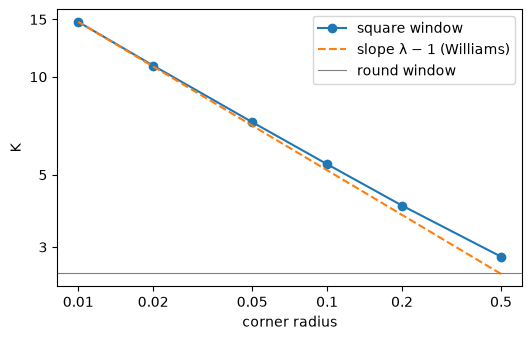

In [6]:
lam = brentq(lambda x: math.sin(1.5 * math.pi * x) - x, 0.3, 0.9)
pairs = list(zip(radii, K))
slopes = [math.log(k2 / k1) / math.log(r2 / r1) for (r1, k1), (r2, k2) in zip(pairs, pairs[1:])]
print("Williams: lambda", lam, "slope", lam - 1)
print("slopes between the radii", [round(s, 3) for s in slopes])

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.loglog(radii, K, "o-", label="square window")
williams = [K[-1] * (r / radii[-1]) ** (lam - 1) for r in radii]
ax.loglog(radii, williams, "--", label="slope λ − 1 (Williams)")
ax.axhline(2.5, color="gray", linewidth=0.8, label="round window")
ax.minorticks_off()
ax.set_xticks(radii, [str(r) for r in radii])
ax.set_yticks([3, 5, 10, 15], ["3", "5", "10", "15"])
ax.set_xlabel("corner radius")
ax.set_ylabel("K")
ax.legend();

## The four windows

The maps show the sum of the principal stresses around a quarter of each window, in the same colors from low in blue
to high in red, with a square window of corner radius 0.2 as the fourth. On the edge, the sum is the stress along the
edge. The tall oval leaves it at 1.5, as far from the window, so the skin hardly notices the window. The wide oval and
the square's corner collect the stress where the load has to pass the window's sides.

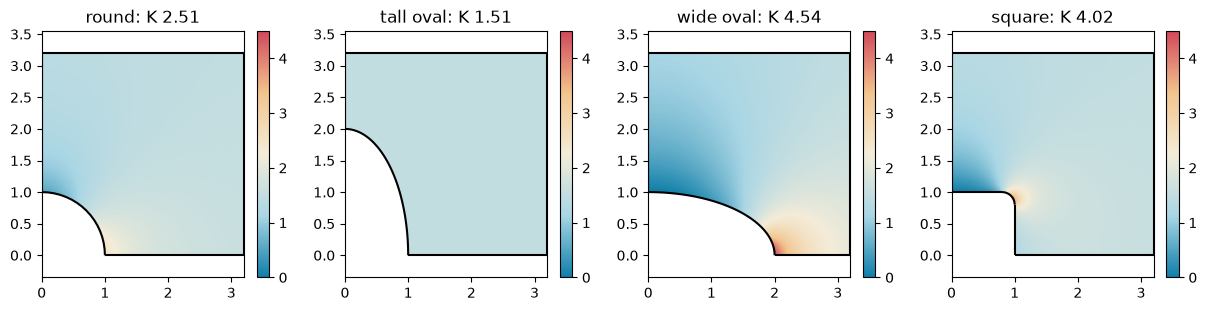

In [7]:
windows["square"] = square(0.2)
solved["square"] = solve(skin(windows["square"], maxh=0.03))

view = px.QuickSketch().Rectangle(3.2, 3.2).Face()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (name, (mesh, sigma, highest, lowest)) in zip(axes, solved.items()):
    px.PlotField(sigma, mesh, skin(windows[name]) * view, ax=ax, min=0, max=4.5, colormap="default_r")
    ax.set_title(f"{name}: K {highest:.2f}")

In [8]:
import sys
sys.path.insert(0, "..")
from gallery import save_figure
save_figure(fig, "airplane-windows", bare=True)